## Project title and summary

ChipScreen is an end-to-end software system that takes raw organ-on-a-chip (OoC) and cell-painting images plus plate metadata as input, and produces QC-checked, explained toxicity and phenotype reports as output with an agent layer that plans the analysis, grounds findings in mechanistic literature, and proposes the next wet-lab experiment.

The system is built from four trained model components ChipTox (multi-task toxicity classification ensemble), ChipCell (cell segmentation + phenotype clustering), GlowFromLight (bright-field → fluorescence image translation), and a QLoRA-fine-tuned Qwen3-4B language model orchestrated by a lightweight planning agent and surfaced through a web interface (desktop and mobile). It directly addresses three of the challenge's named task themes (drug toxicity prediction and response evaluation; bright-field-to-fluorescence image translation; single-cell phenotype analysis) in a single, interoperable pipeline rather than as three disconnected models.

The project targets the End-to-End System category: the emphasis is on a working pipeline — data in, explained decision out rather than a single leaderboard metric.

In [1]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("GDRIVE_API_KEY")

In [2]:
cd "/kaggle/input/datasets/tobimichigan/chipscreen-v2"

/kaggle/input/datasets/tobimichigan/chipscreen-v2


[bootstrap] 'rdkit' not found -> pip install rdkit
[bootstrap] 'imagecodecs' not found -> pip install imagecodecs
[bootstrap] torchao 0.10.0 is older than 0.16.0 -> trying to upgrade it


Failed to load /usr/local/lib/python3.13/dist-packages/torchao/_C_cutlass_90a.abi3.so: Could not load this library: /usr/local/lib/python3.13/dist-packages/torchao/_C_cutlass_90a.abi3.so
Failed to load /usr/local/lib/python3.13/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so: Could not load this library: /usr/local/lib/python3.13/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so
01:51:05 | INFO | [main] root=/kaggle/working/open_datasets | out=/kaggle/working/chipscreen_out
01:51:05 | INFO | [main] device info: {'cuda': True, 'gpu': 'Tesla T4', 'gpu_gb': 15.6}
01:51:06 | INFO | [gdrive] listing folder 'open_datasets' ...
01:51:06 | INFO | [gdrive] listing: 2 files, 13 folders so far (0s), next level 13 folders
01:51:08 | INFO | [gdrive] listing: 316 files, 37 folders so far (2s), next level 24 folders
01:51:09 | INFO | [gdrive] listing: 333 files, 71 folders so far (3s), next level 34 folders
01:51:13 | INFO | [gdrive] listing: 3,794 files, 3,994 folders so 

catalog: file sizes:   0%|          | 0/33913 [00:00<?, ?it/s]

02:00:46 | INFO | [catalog] 33,913 files, 4.77 GB under /kaggle/working/open_datasets
02:00:46 | INFO | 
                         files     gb
source                               
.done.json                   1  0.000
allen_cell_explorer         64  1.997
bbbc                     30148  0.103
bioimage_archive             5  0.000
cell_tracking_challenge    430  0.101
geo                         17  0.004
hpa                          3  0.084
idr                       1375  0.267
jump_cell_painting         181  2.070
livertox                  1385  0.068
pmc_open_access            300  0.057
prism                        2  0.003
tox21_toxcast                2  0.011


schema probe:   0%|          | 0/12 [00:00<?, ?it/s]

...

02:06:56 | INFO | [gdrive] phase 2 (remainder, background): 1,023/23,426 files, 0.35/3.99 GB, 0.9 MB/s, 3 files/s, failed 0, rate-limit hits 0, threads 37, ETA 66 min


atom-pair counts:   0%|          | 0/8097 [00:00<?, ?it/s]

torsion counts:   0%|          | 0/8097 [00:00<?, ?it/s]

RDKit descriptors:   0%|          | 0/8097 [00:00<?, ?it/s]

02:07:16 | INFO | [gdrive] phase 2 (remainder, background): 1,102/23,426 files, 0.36/3.99 GB, 0.9 MB/s, 3 files/s, failed 0, rate-limit hits 0, threads 37, ETA 67 min
02:07:36 | INFO | [gdrive] phase 2 (remainder, background): 1,187/23,426 files, 0.37/3.99 GB, 0.9 MB/s, 3 files/s, failed 0, rate-limit hits 0, threads 37, ETA 69 min
02:07:56 | INFO | [gdrive] phase 2 (remainder, background): 1,272/23,426 files, 0.38/3.99 GB, 0.9 MB/s, 3 files/s, failed 0, rate-limit hits 0, threads 37, ETA 70 min
02:08:16 | INFO | [gdrive] phase 2 (remainder, background): 1,353/23,426 files, 0.39/3.99 GB, 0.9 MB/s, 3 files/s, failed 0, rate-limit hits 0, threads 37, ETA 70 min
02:08:28 | INFO | [mem] chem features: process 2.71 GB | system 9% used | gpu alloc 0.00 GB
02:08:28 | INFO | === ChipTox: data done in 116.4s ===
02:08:28 | INFO | [splits] verified: sizes={'train': 3089, 'val': 1159, 'test': 1533, 'holdout': 2316} fractions={'train': 0.3815, 'val': 0.1431, 'test': 0.1893, 'holdout': 0.286} (no i

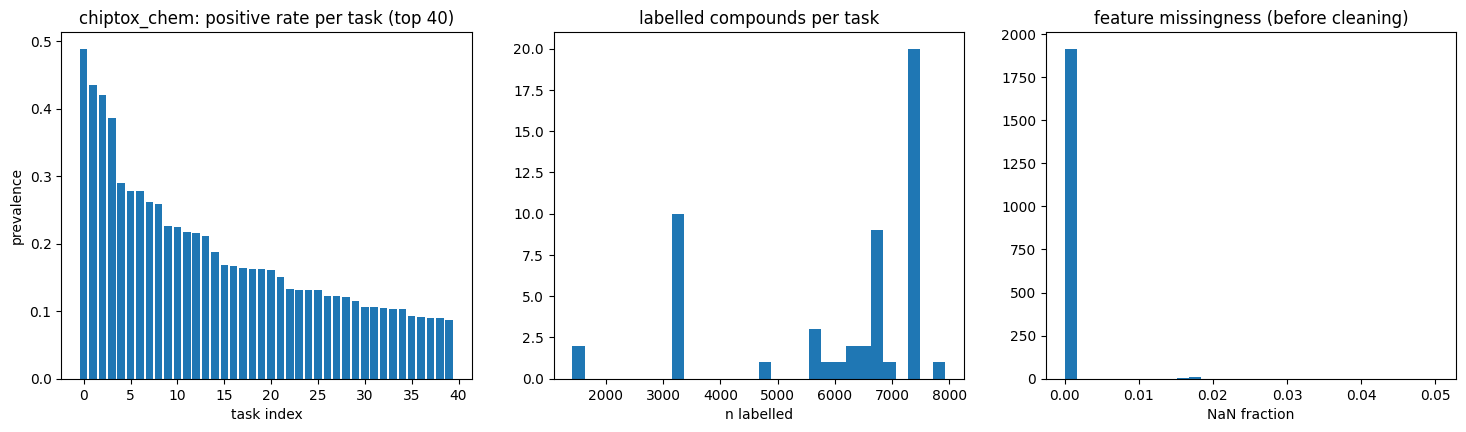

02:08:36 | INFO | [gdrive] phase 2 (remainder, background): 1,438/23,426 files, 0.39/3.99 GB, 0.8 MB/s, 3 files/s, failed 0, rate-limit hits 0, threads 37, ETA 73 min


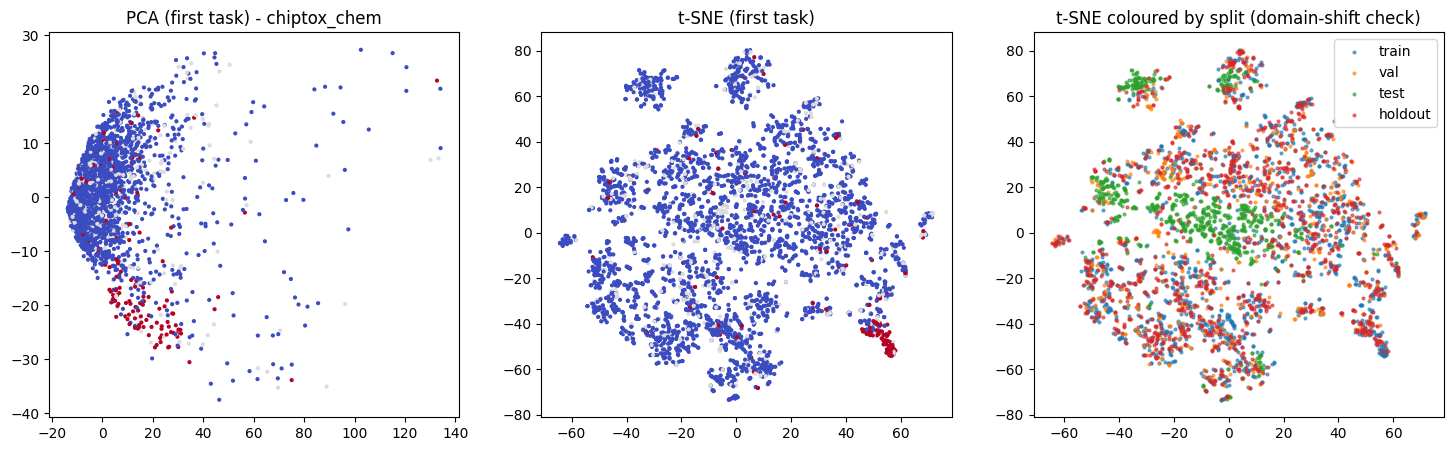

02:08:52 | INFO | [prep] 3975 -> 1662 features after NaN/variance/correlation filtering
02:08:53 | INFO | [chiptox] pool 4248 (train 3089 + val 1159) | test 1533 | holdout 2316 | 1662 features | outliers down-weighted 132
02:08:53 | INFO | === ChipTox: classical members (CV bagging) ===


tune lgbm:   0%|          | 0/3 [00:00<?, ?it/s]

02:08:56 | INFO | [gdrive] phase 2 (remainder, background): 1,525/23,426 files, 0.39/3.99 GB, 0.8 MB/s, 3 files/s, failed 0, rate-limit hits 0, threads 37, ETA 76 min
02:08:56 | INFO | [gdrive] throughput dropped -> threads 28
02:09:16 | INFO | [gdrive] phase 2 (remainder, background): 1,591/23,426 files, 0.40/3.99 GB, 0.8 MB/s, 3 files/s, failed 0, rate-limit hits 0, threads 28, ETA 78 min
02:09:32 | INFO | [chiptox] lgbm tuned params {'colsample_bytree': np.float64(0.20798625466052895), 'learning_rate': np.float64(0.029947971370800568), 'min_child_samples': 78, 'n_estimators': 500, 'num_leaves': 13, 'reg_lambda': np.float64(2.3440174403176073), 'subsample': np.float64(0.7921266556524378)}


tune logreg:   0%|          | 0/3 [00:00<?, ?it/s]

02:09:36 | INFO | [gdrive] phase 2 (remainder, background): 1,658/23,426 files, 0.40/3.99 GB, 0.7 MB/s, 3 files/s, failed 0, rate-limit hits 0, threads 28, ETA 81 min
02:09:36 | INFO | [gdrive] throughput dropped -> threads 24
02:09:56 | INFO | [gdrive] phase 2 (remainder, background): 1,721/23,426 files, 0.40/3.99 GB, 0.7 MB/s, 3 files/s, failed 0, rate-limit hits 0, threads 24, ETA 84 min
02:10:16 | INFO | [gdrive] phase 2 (remainder, background): 1,773/23,426 files, 0.40/3.99 GB, 0.7 MB/s, 3 files/s, failed 0, rate-limit hits 0, threads 24, ETA 87 min
02:10:36 | INFO | [gdrive] phase 2 (remainder, background): 1,828/23,426 files, 0.40/3.99 GB, 0.7 MB/s, 3 files/s, failed 0, rate-limit hits 0, threads 24, ETA 89 min
02:10:56 | INFO | [gdrive] phase 2 (remainder, background): 1,885/23,426 files, 0.40/3.99 GB, 0.6 MB/s, 3 files/s, failed 0, rate-limit hits 0, threads 24, ETA 92 min
02:11:16 | INFO | [gdrive] phase 2 (remainder, background): 1,938/23,426 files, 0.40/3.99 GB, 0.6 MB/s, 3

...

02:56:29 | INFO | [chiptox] attn_mlp L3 fold 3: inner-stop macro-AUROC 0.774


attn_mlp L3 fold 4/5:   0%|          | 0/120 [00:00<?, ?it/s]

02:56:39 | INFO | [chiptox] attn_mlp L3 fold 4: inner-stop macro-AUROC 0.773
02:56:40 | INFO | [gdrive] phase 2 (remainder, background): 16,406/23,426 files, 3.71/3.99 GB, 1.1 MB/s, 5 files/s, failed 0, rate-limit hits 0, threads 24, ETA 4 min


attn_mlp L3 fold 5/5:   0%|          | 0/120 [00:00<?, ?it/s]

02:56:49 | INFO | [chiptox] attn_mlp L3 fold 5: inner-stop macro-AUROC 0.750
02:56:51 | INFO | [chiptox] attn_mlp: reg level 3 -> in-sample minus OOF = 0.140 (target <= 0.08), OOF AUROC 0.779


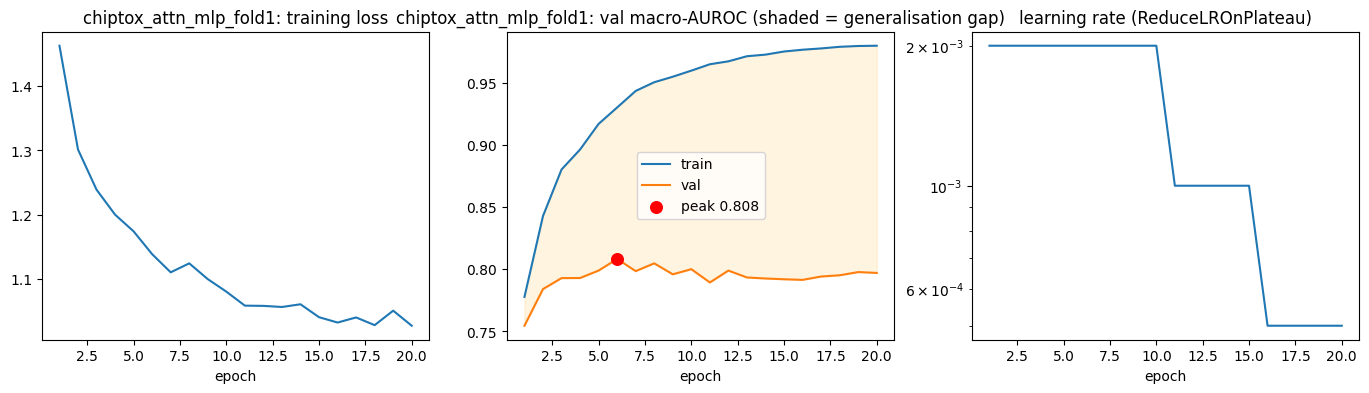

cnn_attn L1 fold 1/5:   0%|          | 0/120 [00:00<?, ?it/s]

02:57:01 | INFO | [gdrive] phase 2 (remainder, background): 16,461/23,426 files, 3.71/3.99 GB, 1.1 MB/s, 5 files/s, failed 0, rate-limit hits 0, threads 24, ETA 4 min
02:57:01 | INFO | [gdrive] throughput still scaling (0.65 vs 0.57) -> threads 37
02:57:21 | INFO | [gdrive] phase 2 (remainder, background): 16,543/23,426 files, 3.71/3.99 GB, 1.1 MB/s, 5 files/s, failed 0, rate-limit hits 0, threads 37, ETA 4 min
02:57:33 | INFO | [chiptox] cnn_attn L1 fold 1: inner-stop macro-AUROC 0.793


cnn_attn L1 fold 2/5:   0%|          | 0/120 [00:00<?, ?it/s]

02:57:41 | INFO | [gdrive] phase 2 (remainder, background): 16,623/23,426 files, 3.72/3.99 GB, 1.1 MB/s, 5 files/s, failed 0, rate-limit hits 0, threads 37, ETA 4 min
02:57:41 | INFO | [gdrive] throughput still scaling (1.02 vs 0.65) -> threads 56
02:58:01 | INFO | [gdrive] phase 2 (remainder, background): 16,739/23,426 files, 3.72/3.99 GB, 1.1 MB/s, 5 files/s, failed 0, rate-limit hits 0, threads 56, ETA 4 min
02:58:05 | INFO | [chiptox] cnn_attn L1 fold 2: inner-stop macro-AUROC 0.769


cnn_attn L1 fold 3/5:   0%|          | 0/120 [00:00<?, ?it/s]

...

03:04:22 | INFO | [gdrive] phase 2 (remainder, background): 20,527/23,426 files, 3.88/3.99 GB, 1.0 MB/s, 5 files/s, failed 0, rate-limit hits 0, threads 96, ETA 2 min
03:04:35 | INFO | [chiptox] cnn_attn L3 fold 3: inner-stop macro-AUROC 0.756


cnn_attn L3 fold 4/5:   0%|          | 0/120 [00:00<?, ?it/s]

03:04:42 | INFO | [gdrive] phase 2 (remainder, background): 20,733/23,426 files, 3.89/3.99 GB, 1.0 MB/s, 5 files/s, failed 0, rate-limit hits 0, threads 96, ETA 2 min
03:05:02 | INFO | [gdrive] phase 2 (remainder, background): 20,939/23,426 files, 3.90/3.99 GB, 1.0 MB/s, 5 files/s, failed 0, rate-limit hits 0, threads 96, ETA 2 min
03:05:02 | INFO | [chiptox] cnn_attn L3 fold 4: inner-stop macro-AUROC 0.758


cnn_attn L3 fold 5/5:   0%|          | 0/120 [00:00<?, ?it/s]

03:05:22 | INFO | [gdrive] phase 2 (remainder, background): 21,144/23,426 files, 3.90/3.99 GB, 1.0 MB/s, 5 files/s, failed 0, rate-limit hits 0, threads 96, ETA 1 min
03:05:35 | INFO | [chiptox] cnn_attn L3 fold 5: inner-stop macro-AUROC 0.752
03:05:38 | INFO | [chiptox] cnn_attn: reg level 3 -> in-sample minus OOF = 0.091 (target <= 0.08), OOF AUROC 0.760


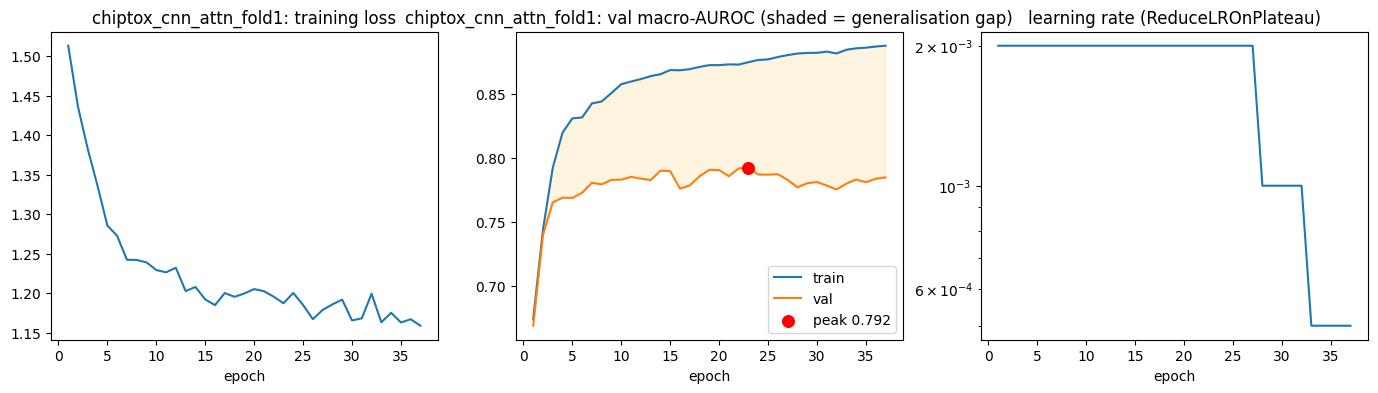

03:05:38 | INFO | === ChipTox: deep members (CV bagging) done in 673.3s ===
03:05:40 | INFO | [chiptox] OOF blend weights: {'lgbm': 0.167, 'logreg': 0.167, 'rf': 0.167, 'attn_mlp': 0.167, 'cnn_attn': 0.333}
03:05:42 | INFO | [gdrive] phase 2 (remainder, background): 21,358/23,426 files, 3.91/3.99 GB, 1.0 MB/s, 5 files/s, failed 0, rate-limit hits 0, threads 96, ETA 1 min
03:05:53 | INFO | [chiptox] selected 'ensemble': train(in-sample) 0.922 | OOF 0.806 | test 0.760 | HOLDOUT 0.800
03:05:53 | INFO | 
             train_auroc  val_auroc  test_auroc  holdout_auroc  holdout_balacc  selection_score
lgbm               0.816      0.762       0.689          0.766           0.704            0.689
logreg             0.957      0.790       0.731          0.772           0.709            0.680
rf                 0.825      0.775       0.690          0.760           0.695            0.690
attn_mlp           0.919      0.795       0.755          0.791           0.723            0.725
cnn_attn      

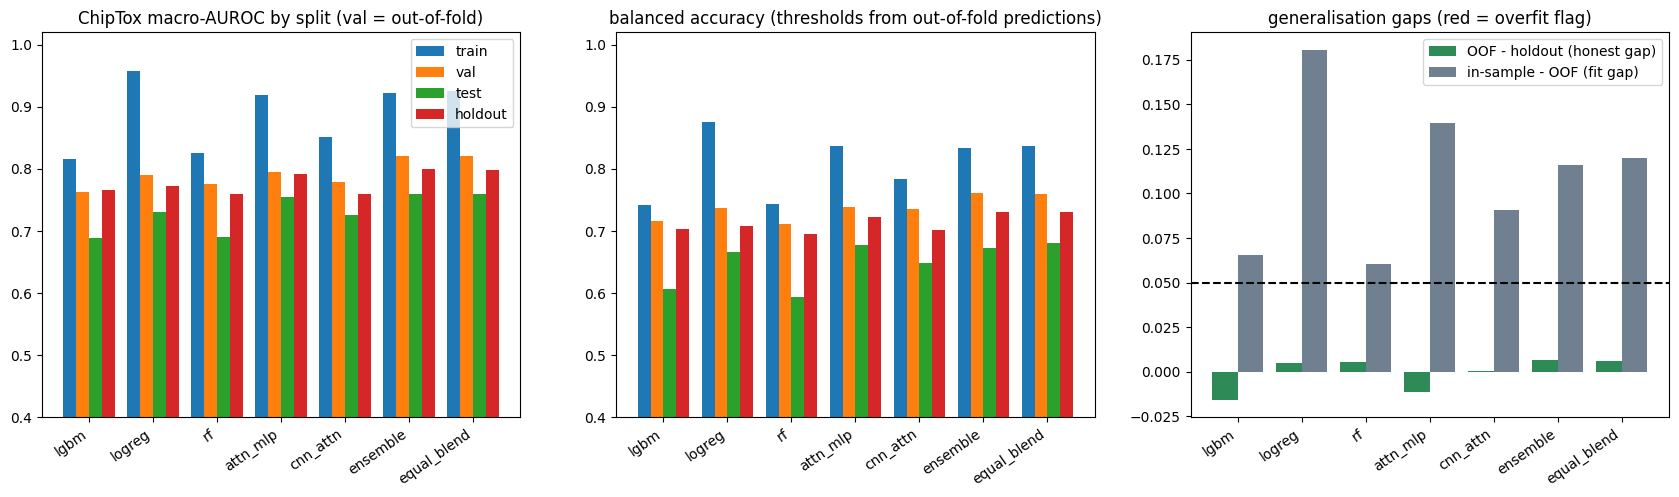

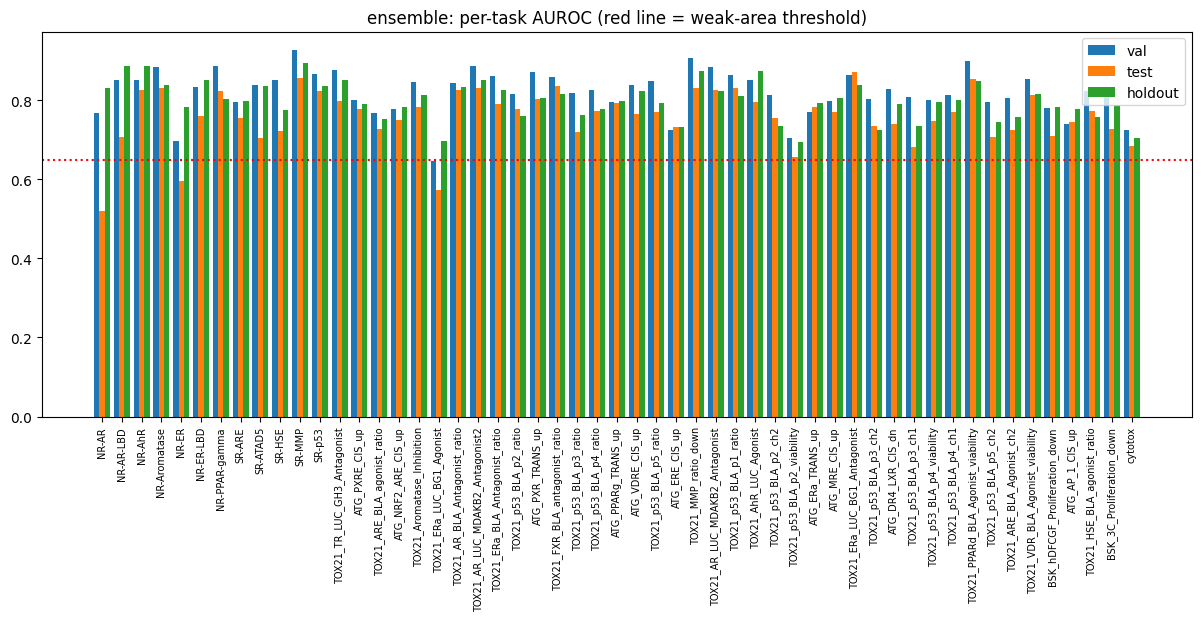

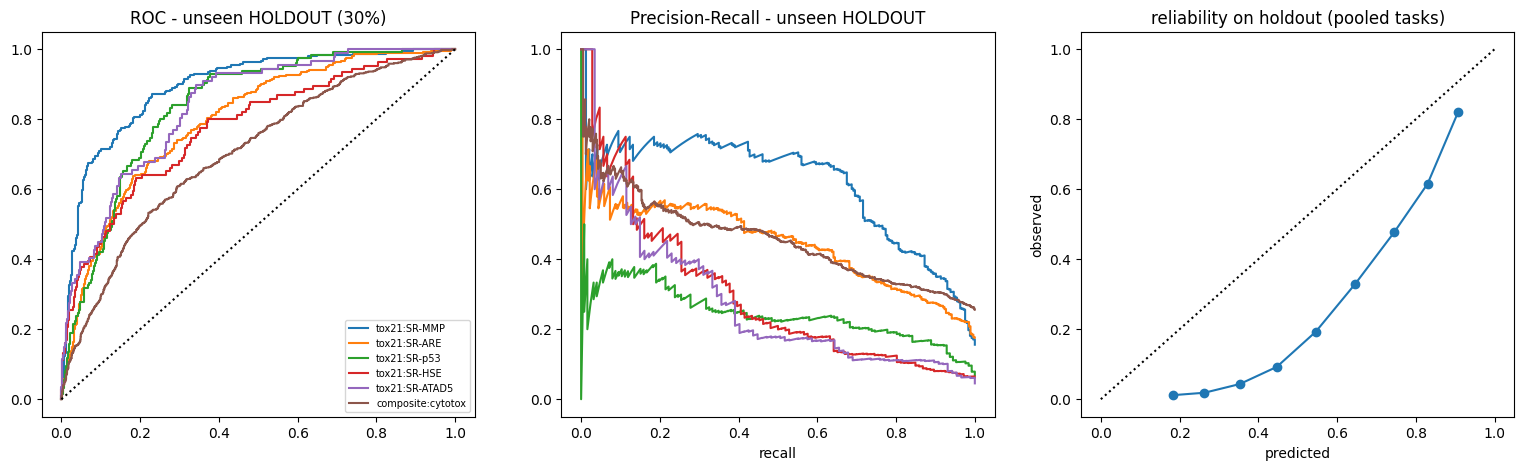

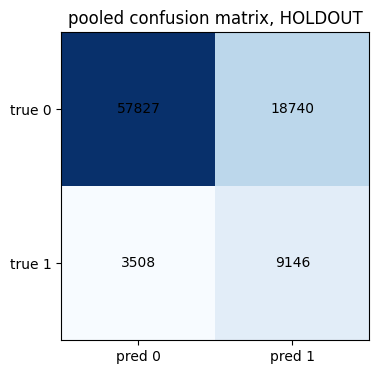

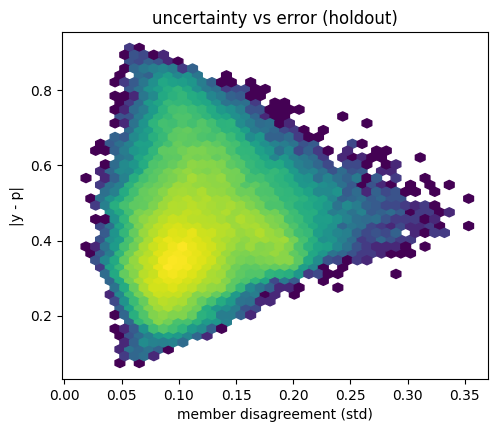

03:05:57 | INFO | [multimodal] overlapping compounds {'n_overlap': 99, 'per_split': {'train': 47, 'val': 18, 'test': 6, 'holdout': 28}}
03:05:57 | INFO | [multimodal] overlap too small for a 4-way split ({'train': 47, 'val': 18, 'test': 6, 'holdout': 28}) -> repeated scaffold-grouped CV on the 99 overlapping compounds
03:05:57 | INFO | [prep] 3975 -> 1263 features after NaN/variance/correlation filtering
03:05:57 | INFO | [prep] 3651 -> 799 features after NaN/variance/correlation filtering
03:06:02 | INFO | [gdrive] phase 2 (remainder, background): 21,571/23,426 files, 3.92/3.99 GB, 1.0 MB/s, 6 files/s, failed 0, rate-limit hits 0, threads 96, ETA 1 min
03:06:22 | INFO | [gdrive] phase 2 (remainder, background): 21,784/23,426 files, 3.93/3.99 GB, 1.0 MB/s, 6 files/s, failed 0, rate-limit hits 0, threads 96, ETA 1 min
03:06:42 | INFO | [gdrive] phase 2 (remainder, background): 21,997/23,426 files, 3.94/3.99 GB, 1.0 MB/s, 6 files/s, failed 0, rate-limit hits 0, threads 96, ETA 1 min
03:0

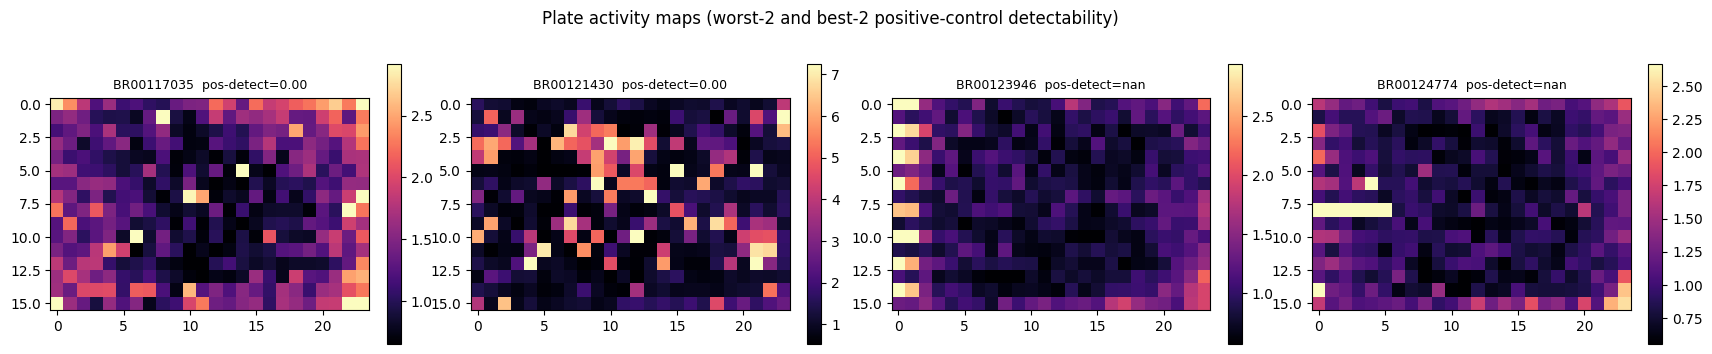

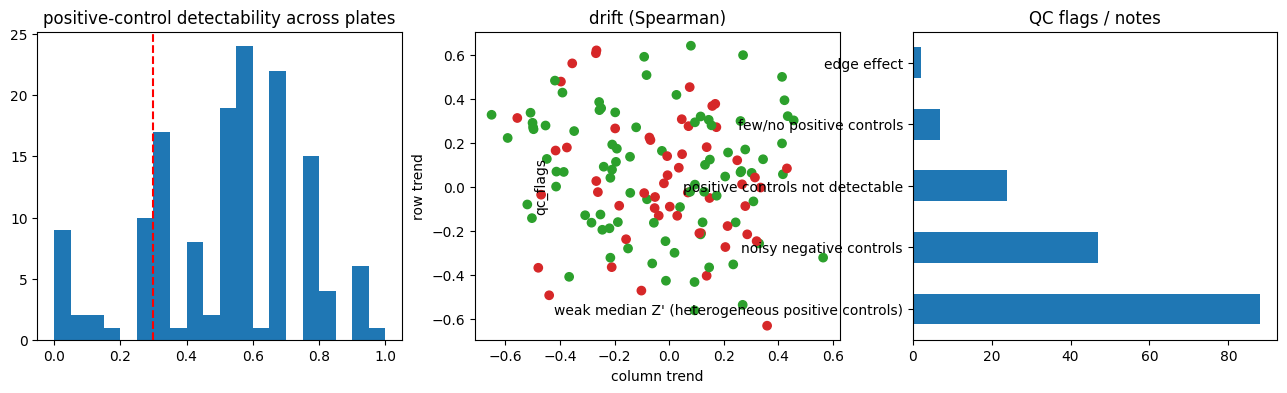

03:09:02 | INFO | [dosecurve] 151 plates: 95 pass | median per-control Z'=-3.28, best-control Z'=-3.21 | median pos-detect=0.58
qc_flags
weak median Z' (heterogeneous positive controls)    88
noisy negative controls                             47
positive controls not detectable                    24
few/no positive controls                             7
edge effect                                          2
03:09:02 | WARNING | [dosecurve] BBBC021 image CSV found but raw DAPI TIFFs were not downloaded (BBBC_INCLUDE_IMAGES=False) -> dose-response from images unavailable


scan for dose-response tables:   0%|          | 0/92 [00:00<?, ?it/s]

03:09:03 | INFO | === DoseCurve QC Workbench done in 3.0s ===
03:09:04 | INFO | [main] stage 'dose' finished in 5s
03:09:06 | INFO | [mem] after dose: process 3.67 GB | system 12% used | gpu alloc 0.02 GB
03:09:06 | INFO | === GlowFromLight ===
03:09:07 | INFO | [glow] channel statistics (volume 0):
 ch  med_over_p998  skew  fg_frac    cv
  0          0.860 1.847    0.323 0.032
  1          0.301 2.117    0.135 0.358
  2          0.504 5.890    0.279 0.125
03:09:07 | INFO | [glow] MODE = bright-field -> fluorescence | input channel 0 | targets {'dna': 1, 'membrane': 2} | channel 0 identified as transmitted light from image statistics


GlowFromLight: reading volumes:   0%|          | 0/63 [00:00<?, ?it/s]

03:10:06 | INFO | [glow] dataset: 1134 slices from 63 volumes, targets ['dna', 'membrane'], 418 MB
03:10:06 | INFO | [splits] verified: sizes={'train': 450, 'val': 180, 'test': 162, 'holdout': 342} fractions={'train': 0.3968, 'val': 0.1587, 'test': 0.1429, 'holdout': 0.3016} (no index/group leakage)


GlowFromLight training:   0%|          | 0/60 [00:00<?, ?it/s]

03:19:27 | INFO | [glow] train-val Pearson gap 0.128 > 0.12 -> retraining with 2x regularisation


GlowFromLight training:   0%|          | 0/60 [00:00<?, ?it/s]

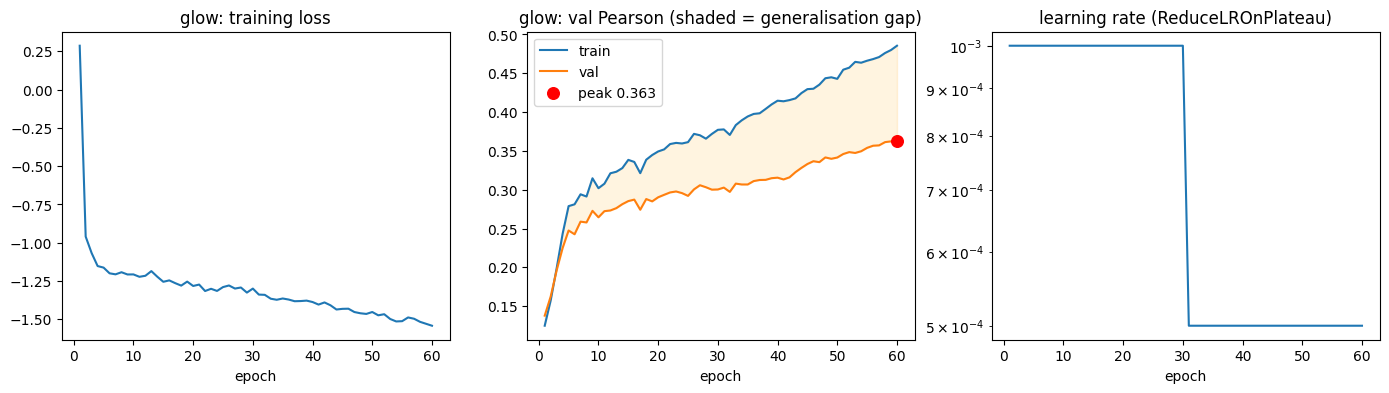

03:28:25 | INFO | [glow] HOLDOUT Pearson  model vs mean-image baseline: dna: 0.373 vs 0.045; membrane: 0.111 vs 0.056
03:28:28 | INFO | [glow] trust-map validation: {'test': {'spearman_trust_vs_error': -0.38580617927391464, 'err_low_trust': 0.13611073791980743, 'err_high_trust': 0.0608501136302948, 'ratio': 2.2368197441101074, 'coverage_2sigma': 0.9400236237032751}, 'holdout': {'spearman_trust_vs_error': -0.41184823364113327, 'err_low_trust': 0.13916975259780884, 'err_high_trust': 0.05804864689707756, 'ratio': 2.397467613220215, 'coverage_2sigma': 0.9480029645873944}}


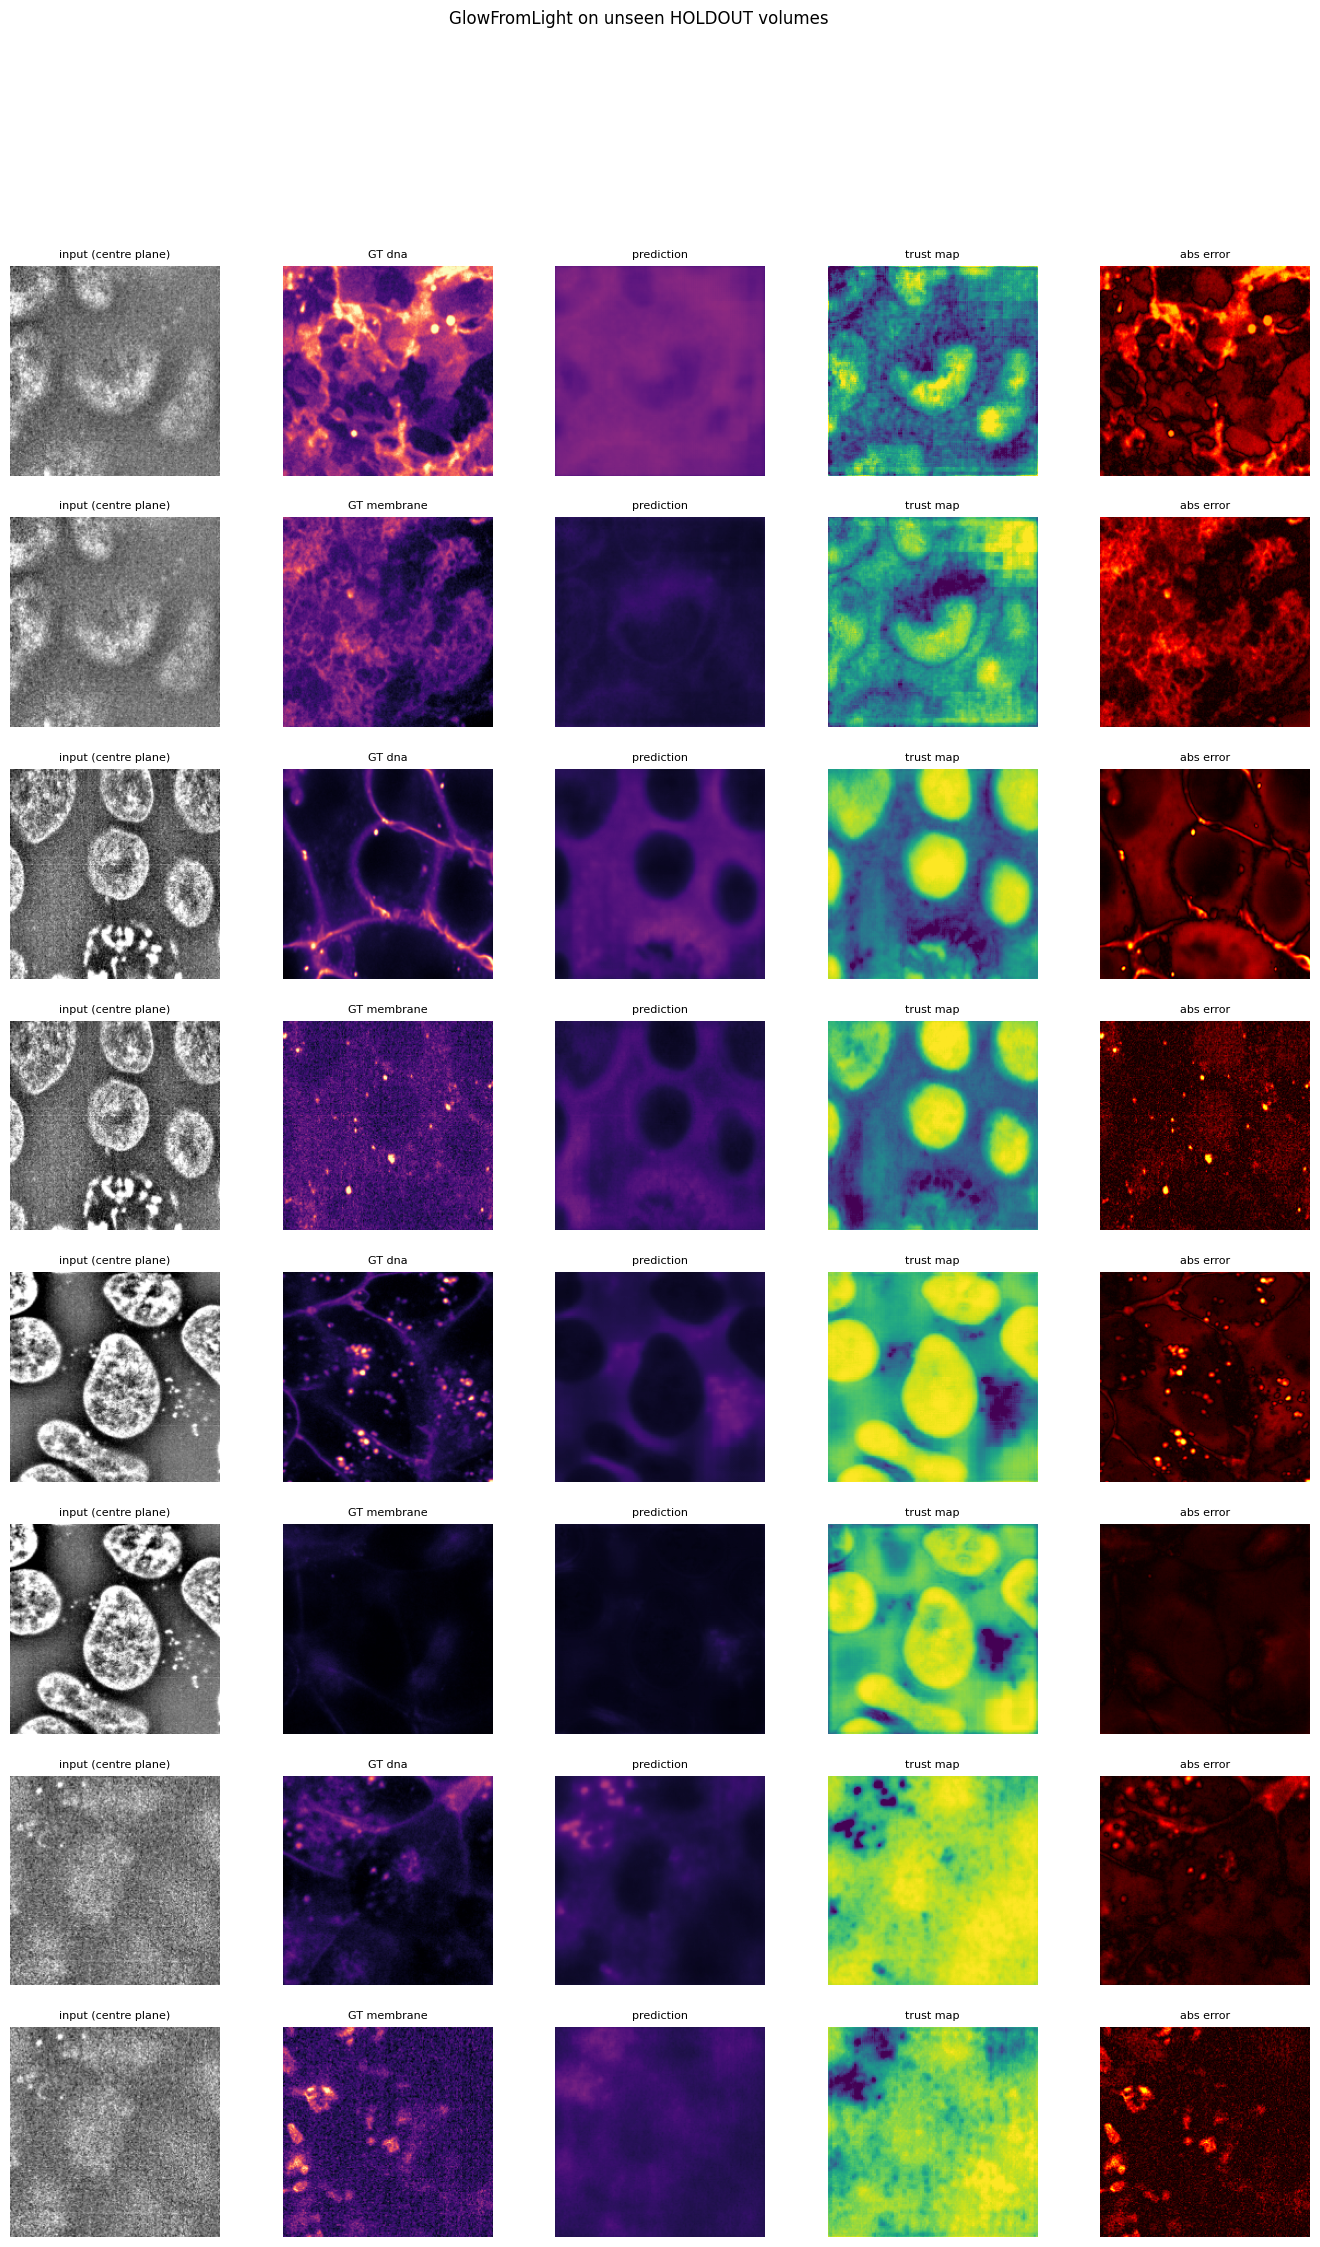

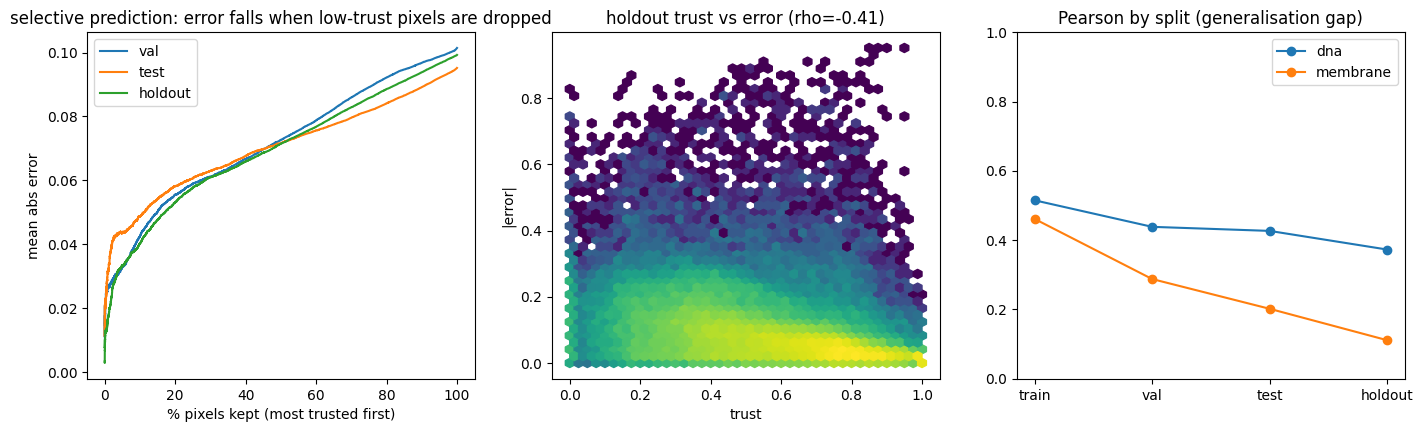

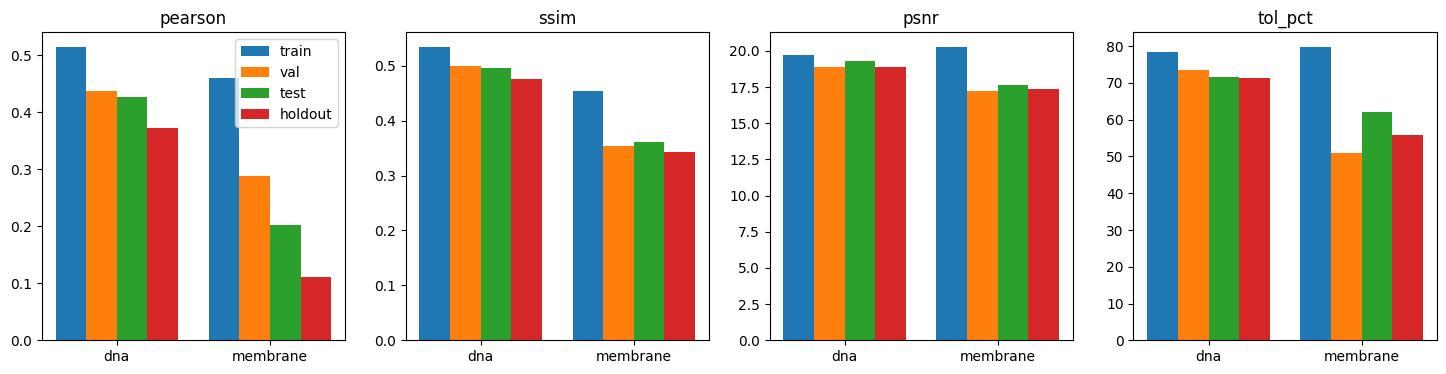

03:28:36 | INFO | === GlowFromLight done in 1170.0s ===
03:28:38 | INFO | [main] stage 'glow' finished in 1172s
03:28:40 | INFO | [mem] after glow: process 4.48 GB | system 14% used | gpu alloc 0.04 GB
03:28:40 | INFO | === ChipCell Atlas ===


BBBC038: images+masks:   0%|          | 0/670 [00:00<?, ?it/s]

03:28:57 | INFO | [chipcell] BBBC038: 670 loaded, 0 skipped


CTC: raw+GT pairs:   0%|          | 0/188 [00:00<?, ?it/s]

03:29:01 | INFO | [chipcell] CTC: 188 loaded, 0 skipped
03:29:21 | INFO | [chipcell] segmentation set: 858 images ({'bbbc038': 670, 'ctc:Fluo-N2DH-GOWT1': 50, 'ctc:Fluo-C2DL-MSC': 48, 'ctc:BF-C2DL-HSC': 38, 'ctc:PhC-C2DH-U373': 34, 'ctc:DIC-C2DH-HeLa': 18}), 337 MB
03:29:21 | INFO | [splits] verified: sizes={'train': 343, 'val': 129, 'test': 129, 'holdout': 257} fractions={'train': 0.3998, 'val': 0.1503, 'test': 0.1503, 'holdout': 0.2995} (no index/group leakage)


segmentation targets:   0%|          | 0/343 [00:00<?, ?it/s]

ChipCell segmentation training:   0%|          | 0/60 [00:00<?, ?it/s]

03:42:32 | INFO | [chipcell] train-val Dice gap 0.127 > 0.08 -> retraining with 2x regularisation


segmentation targets:   0%|          | 0/343 [00:00<?, ?it/s]

ChipCell segmentation training:   0%|          | 0/60 [00:00<?, ?it/s]

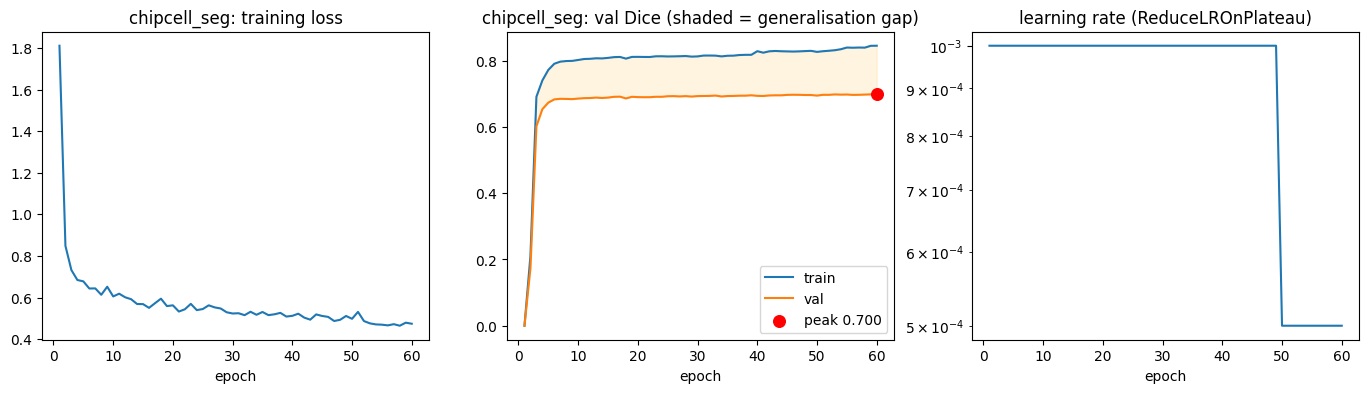

03:54:35 | INFO | [chipcell] foreground threshold tuned on validation: 0.65


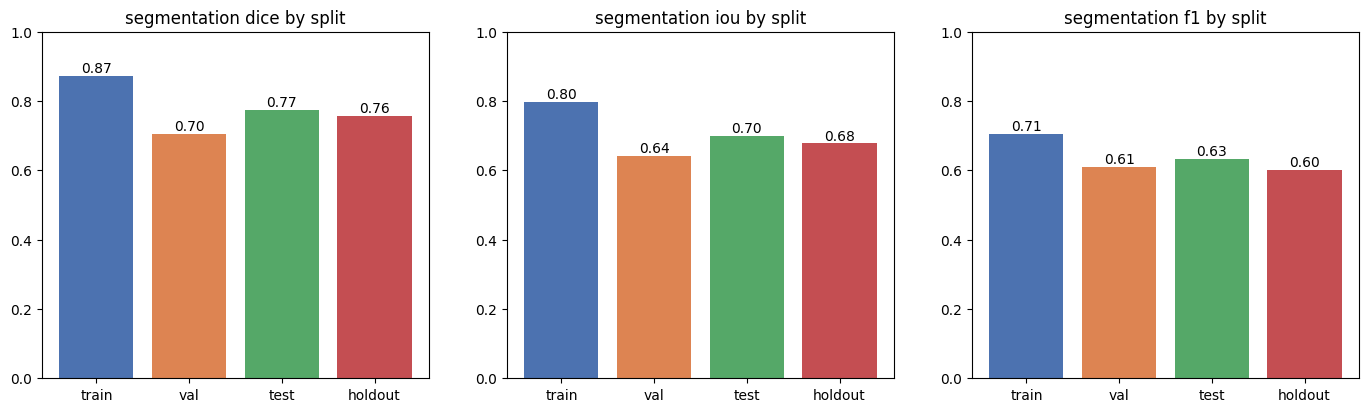

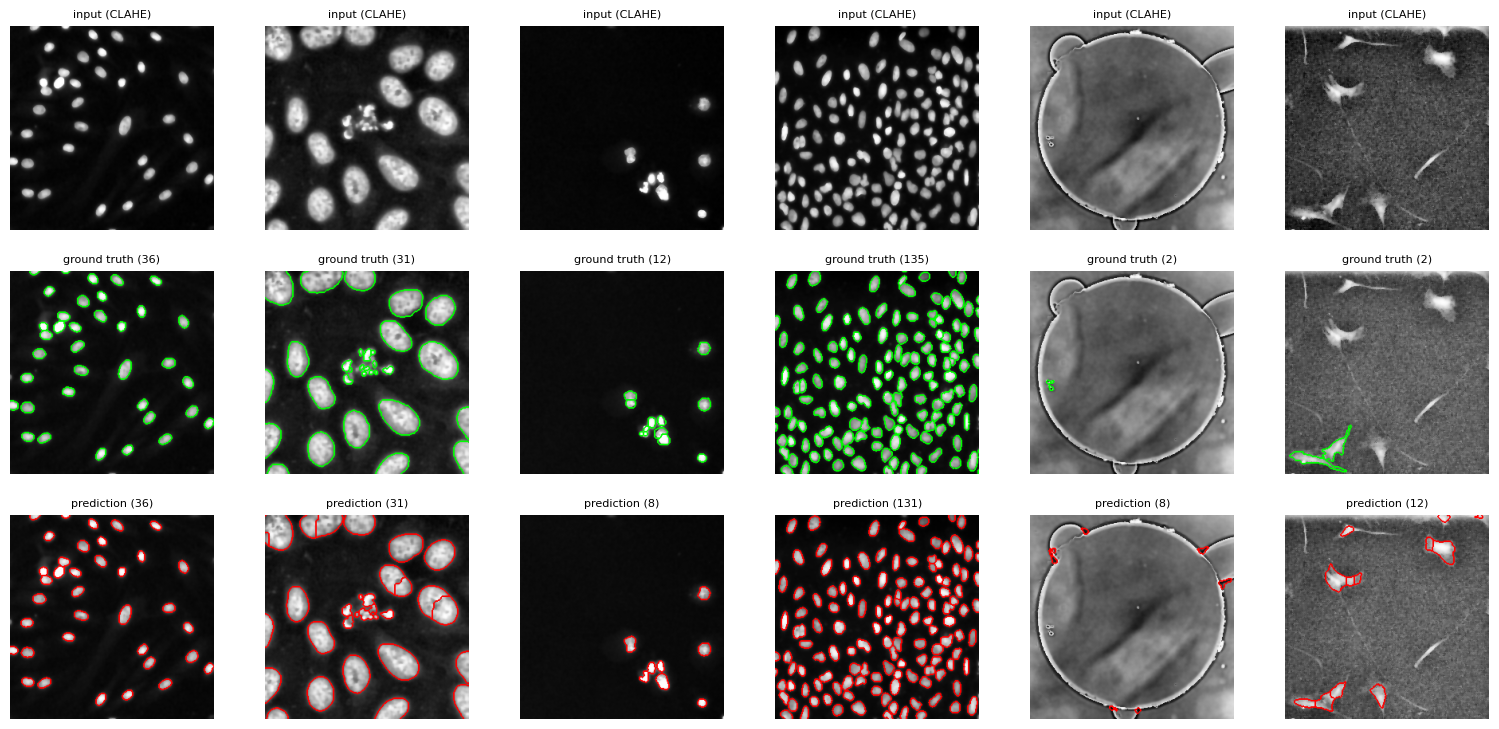

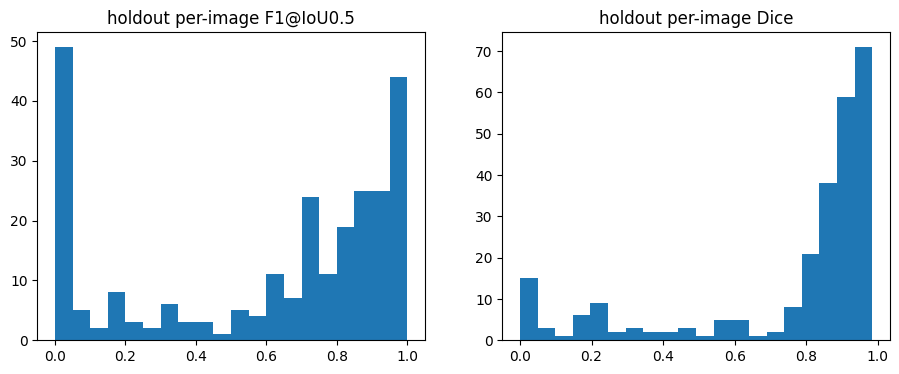

cell features (holdout):   0%|          | 0/150 [00:00<?, ?it/s]

03:55:36 | INFO | [prep] 15 -> 14 features after NaN/variance/correlation filtering


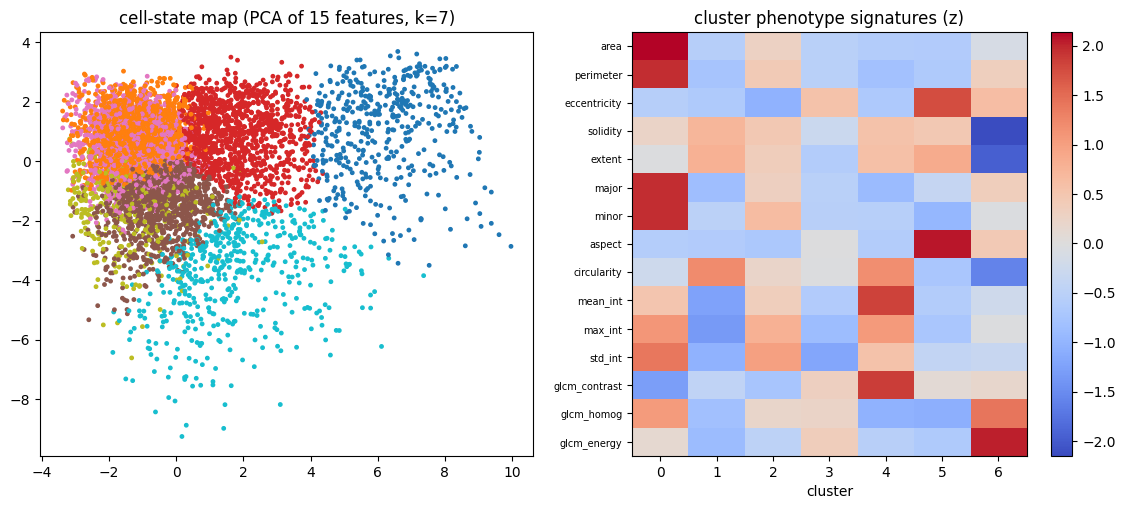

03:55:37 | INFO | === ChipCell Atlas done in 1616.8s ===
03:55:39 | INFO | [main] stage 'cell' finished in 1619s
03:55:41 | INFO | [mem] after cell: process 5.09 GB | system 16% used | gpu alloc 0.06 GB
03:55:41 | INFO | [llm] selected Qwen/Qwen2.5-1.5B-Instruct (licence apache-2.0)
03:55:42 | INFO | [llm] instruction data: train=421 (21 plans), val=45 (5 plans), test=46 (6 plans)


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

04:14:11 | INFO | [agent] planner: rule-based
04:14:11 | INFO | [agent] PLAN (shown before execution):
{
  "goal": "Assess the toxicity of the screened compounds, check plate quality and dose-response, and propose the next experiment.",
  "steps": [
    {
      "id": 1,
      "tool": "plate_qc",
      "inputs": {},
      "expected": "per-plate Z' / edge / drift flags",
      "depends_on": []
    },
    {
      "id": 2,
      "tool": "dose_response",
      "inputs": {},
      "expected": "4PL fits with CI and quality flags",
      "depends_on": [
        1
      ]
    },
    {
      "id": 3,
      "tool": "score_toxicity",
      "inputs": {
        "smiles": []
      },
      "expected": "toxicity probabilities with uncertainty",
      "depends_on": [
        1
      ]
    },
    {
      "id": 4,
      "tool": "retrieve_literature",
      "inputs": {
        "query": "Assess the toxicity of the screened compounds, check plate quality and dose-response, and propose the next experiment."


ChipAgent: executing plan:   0%|          | 0/6 [00:00<?, ?it/s]

04:14:40 | INFO | [agent] done in 41.1s -> /kaggle/working/chipscreen_out/reports/chipscreen_agent_report.md
04:14:42 | INFO | [main] stage 'agent' finished in 126s
04:14:43 | INFO | [mem] after agent: process 5.56 GB | system 18% used | gpu alloc 0.16 GB


catalog: file sizes:   0%|          | 0/57137 [00:00<?, ?it/s]

04:14:49 | INFO | [catalog] 57,137 files, 8.76 GB under /kaggle/working/open_datasets
04:14:49 | INFO | 
                         files     gb
source                               
.done.json                   1  0.000
HSA_chipscreen.zip           1  0.000
allen_cell_explorer         64  1.997
aop_wiki                     8  0.111
bbbc                     34200  0.414
bioimage_archive           472  0.495
cell_tracking_challenge  17044  2.399
geo                         17  0.004
hpa                          4  0.179
idr                       1410  0.747
jump_cell_painting         185  2.070
livertox                  3427  0.271
pmc_open_access            300  0.057
prism                        2  0.003
tox21_toxcast                2  0.011
04:14:49 | INFO | 
CHIPSCREEN PIPELINE SUMMARY
runtime 8624s | plots saved: 20 in /kaggle/working/chipscreen_out/plots

ChipTox  best=ensemble  holdout macro-AUROC=0.800  bal.acc=0.730  honest gap (OOF-holdout)=0.006  fit gap (in-sample-OOF)=0.116  

In [3]:
import sys; sys.path.insert(0, "/kaggle/working/chipscreen")
from main import run_pipeline
out = run_pipeline() # sync Drive -> catalog -> jump -> chiptox -> dosecurve -> glow -> chipcell -> llm -> agent